# Experiment 5: POS Tagging, Chunking and Parsing

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Categorizing and tagging words in Twitter data.
2. Study and implementation of POS tagging and chunking in a sentence.

**Data:** 1,000 real tweets from NLTK's `twitter_samples` corpus, saved as `tweets.csv` in this folder.

## Step 1: Install and import the required packages

In [1]:
%pip install nltk spacy pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import re
import pandas as pd
import nltk
import spacy
from nltk import pos_tag, word_tokenize
from nltk.tokenize import TweetTokenizer

for pkg in ["twitter_samples", "universal_tagset", "punkt", "punkt_tab", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

### Chart style

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

# Part 1: Categorizing and tagging words in Twitter data

**POS tagging** labels each word with its grammatical category. The **universal tagset** uses: NOUN, VERB, ADJ, ADV, PRON, DET, ADP (preposition), NUM, CONJ, PRT (particle), `.` (punctuation) and X (other). Tweets are hard to tag because they contain @mentions, #hashtags, links, emoticons and slang.

## 1.1 Load and tokenize the tweets
`TweetTokenizer` keeps mentions, hashtags, URLs and emoticons as single tokens.

In [4]:
if not os.path.exists("tweets.csv"):
    from nltk.corpus import twitter_samples
    raw = twitter_samples.docs("tweets.20150430-223406.json")[:1000]
    pd.DataFrame({"tweet_id": [t["id"] for t in raw], "text": [t["text"] for t in raw]}).to_csv(
        "tweets.csv", index=False, encoding="utf-8")

tweets = pd.read_csv("tweets.csv")
tweets["tokens"] = tweets["text"].apply(TweetTokenizer(reduce_len=True).tokenize)
print(f"{len(tweets)} tweets, {tweets['tokens'].str.len().sum():,} tokens")
print(tweets["tokens"][2])

1000 tweets, 22,641 tokens
['RT', '@LabourEoin', ':', 'The', 'economy', 'was', 'growing', '3', 'times', 'faster', 'on', 'the', 'day', 'David', 'Cameron', 'became', 'Prime', 'Minister', 'than', 'it', 'is', 'today', '..', '#BBCqt', 'http://t.co…']


## 1.2 Categorizing the tokens

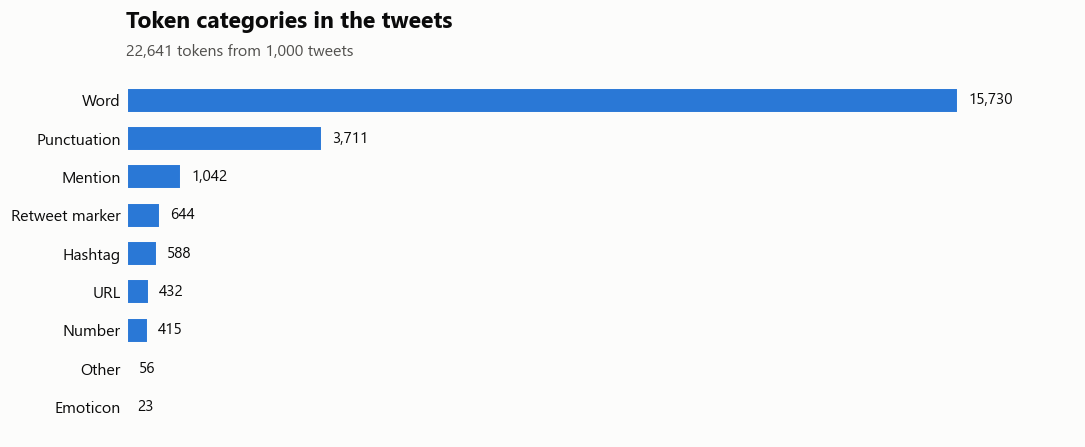

In [5]:
EMOTICON = r"^(?:[<>]?[:;=8xX][\-o\*']?[\)\]\(\[dDpP/\\:\}\{@\|]+|<3|\^_?\^)$"

def token_category(tok):
    if tok.startswith("@") and len(tok) > 1:  return "Mention"
    if tok.startswith("#") and len(tok) > 1:  return "Hashtag"
    if re.match(r"https?://|www\.", tok):     return "URL"
    if tok == "RT":                            return "Retweet marker"
    if re.match(EMOTICON, tok):                return "Emoticon"
    if any(c.isdigit() for c in tok) and re.fullmatch(r"[\d.,:/%£$]+", tok): return "Number"
    if re.fullmatch(r"[A-Za-z]+(?:['\-][A-Za-z]+)*", tok): return "Word"
    if re.fullmatch(r"[^\w\s]+", tok):         return "Punctuation"
    return "Other"

all_tokens = [t for ts in tweets["tokens"] for t in ts]
cats = pd.Series([token_category(t) for t in all_tokens]).value_counts()

fig, ax = plt.subplots(figsize=(10, 4.2))
hbar(ax, cats.index, cats.values)
titles(ax, "Token categories in the tweets", f"{len(all_tokens):,} tokens from {len(tweets):,} tweets")
plt.tight_layout()
plt.show()

## 1.3 Tagging with NLTK's standard tagger
`nltk.pos_tag` was trained on newspaper text, so it forces Twitter-specific tokens into normal word classes:

In [6]:
print(pos_tag(tweets["tokens"][2], tagset="universal"))

[('RT', 'NOUN'), ('@LabourEoin', 'NOUN'), (':', '.'), ('The', 'DET'), ('economy', 'NOUN'), ('was', 'VERB'), ('growing', 'VERB'), ('3', 'NUM'), ('times', 'NOUN'), ('faster', 'ADV'), ('on', 'ADP'), ('the', 'DET'), ('day', 'NOUN'), ('David', 'NOUN'), ('Cameron', 'NOUN'), ('became', 'VERB'), ('Prime', 'NOUN'), ('Minister', 'NOUN'), ('than', 'ADP'), ('it', 'PRON'), ('is', 'VERB'), ('today', 'NOUN'), ('..', 'NOUN'), ('#BBCqt', 'NOUN'), ('http://t.co…', 'NOUN')]


`RT`, `@LabourEoin`, `#BBCqt` and the link are all tagged NOUN.

## 1.4 A Twitter-aware tagger
Rules tag the Twitter-specific tokens with their own tags (MENTION, HASHTAG, URL, EMOTICON, RT, and INTJ for slang like *lol*); only the remaining words are sent to `pos_tag`.

In [7]:
SLANG = {"lol", "lmao", "omg", "haha", "hahaha", "wow", "yay", "ugh", "hmm", "yeah", "ok", "okay"}
RULE_TAGS = {"Mention": "MENTION", "Hashtag": "HASHTAG", "URL": "URL", "Emoticon": "EMOTICON", "Retweet marker": "RT"}

def twitter_tag(tokens):
    tags = [RULE_TAGS.get(token_category(t)) or ("INTJ" if t.lower() in SLANG else None) for t in tokens]
    rest = [i for i, t in enumerate(tags) if t is None]
    for i, (_, tag) in zip(rest, pos_tag([tokens[i] for i in rest], tagset="universal")):
        tags[i] = tag
    return list(zip(tokens, tags))

tweets["tagged"] = tweets["tokens"].apply(twitter_tag)
print(tweets["tagged"][2])

[('RT', 'RT'), ('@LabourEoin', 'MENTION'), (':', '.'), ('The', 'DET'), ('economy', 'NOUN'), ('was', 'VERB'), ('growing', 'VERB'), ('3', 'NUM'), ('times', 'NOUN'), ('faster', 'ADV'), ('on', 'ADP'), ('the', 'DET'), ('day', 'NOUN'), ('David', 'NOUN'), ('Cameron', 'NOUN'), ('became', 'VERB'), ('Prime', 'NOUN'), ('Minister', 'NOUN'), ('than', 'ADP'), ('it', 'PRON'), ('is', 'VERB'), ('today', 'NOUN'), ('..', 'NOUN'), ('#BBCqt', 'HASHTAG'), ('http://t.co…', 'URL')]


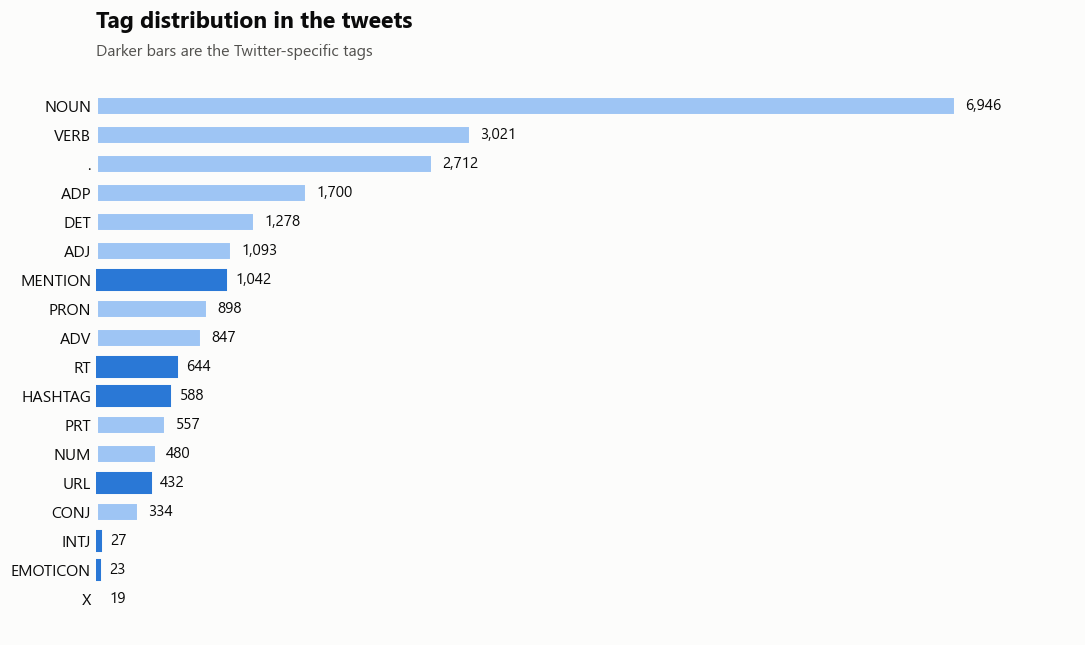

In [8]:
tag_counts = pd.Series([t for s in tweets["tagged"] for _, t in s]).value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
hbar(ax, tag_counts.index, tag_counts.values, color=BLUE_LIGHT)
for bar, lab in zip(ax.patches, list(tag_counts.index)[::-1]):
    if lab in set(RULE_TAGS.values()) | {"INTJ"}:
        bar.set_color(BLUE)
titles(ax, "Tag distribution in the tweets", "Darker bars are the Twitter-specific tags")
plt.tight_layout()
plt.show()

# Part 2: POS tagging and chunking in a sentence

## 2.1 POS tagging
Penn Treebank tags from NLTK, with their meanings and the universal tag.

In [9]:
sentence = "The young Indian scientist quickly wrote a detailed report on the new climate policy."
tags = pos_tag(word_tokenize(sentence))

pd.DataFrame({"Word": [w for w, _ in tags], "Penn tag": [t for _, t in tags],
              "Meaning": [re.sub(r" \(English\).*", "", spacy.explain(t) or "") for _, t in tags],
              "Universal tag": [t for _, t in pos_tag([w for w, _ in tags], tagset="universal")]})

,Word,Penn tag,Meaning,Universal tag
0,The,DT,determiner,DET
1,young,JJ,adjective,ADJ
2,Indian,JJ,adjective,ADJ
3,scientist,NN,"noun, singular or mass",NOUN
4,quickly,RB,adverb,ADV
5,wrote,VBD,"verb, past tense",VERB
6,a,DT,determiner,DET
7,detailed,JJ,adjective,ADJ
8,report,NN,"noun, singular or mass",NOUN
9,on,IN,"conjunction, subordinating or preposition",ADP


## 2.2 Chunking
**Chunking** groups tagged words into non-overlapping phrases: **NP** (noun phrase), **VP** (verb phrase), **PP** (prepositional phrase). NLTK's `RegexpParser` uses a grammar of regular expressions over POS tags, e.g. `NP: {<DT>?<JJ>*<NN.*>+}` = optional determiner, any adjectives, one or more nouns.

(S
  (NP The/DT young/JJ Indian/JJ scientist/NN)
  quickly/RB
  wrote/VBD
  (NP a/DT detailed/JJ report/NN)
  on/IN
  (NP the/DT new/JJ climate/NN policy/NN)
  ./.)


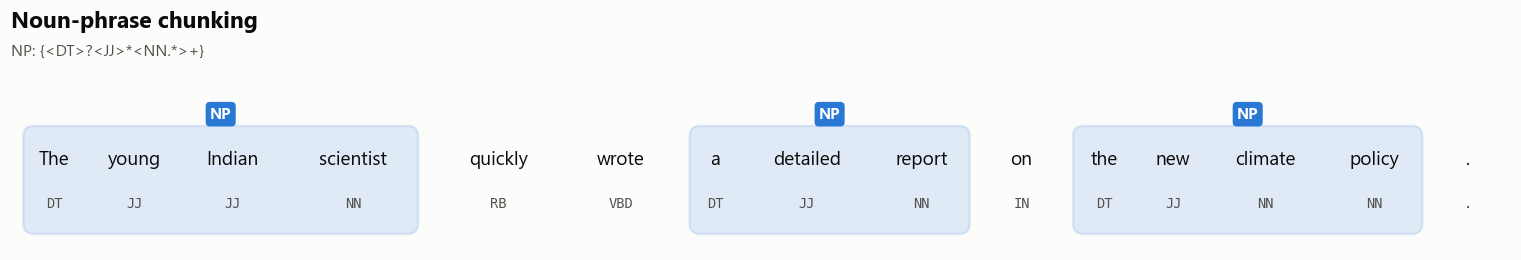

In [10]:
from nltk import RegexpParser, Tree
from matplotlib.patches import FancyBboxPatch

CHUNK_COLORS = {"NP": "#2a78d6", "VP": "#eb6834", "PP": "#1baf7a"}

def chunk_diagram(tree, title, subtitle=None):
    """Draw words, their POS tags and a coloured box around each chunk."""
    groups = [(st.label(), st.leaves()) if isinstance(st, Tree) else (None, [st]) for st in tree]
    x, words, spans = 0.0, [], []
    for label, toks in groups:
        start = x
        for w, t in toks:
            width = max(len(w), len(t)) * 0.13 + 0.4
            words.append((x + width / 2, w, t))
            x += width
        spans.append((label, start, x))
        x += 0.22
    fig, ax = plt.subplots(figsize=(max(7, x * 0.82), 2.5))
    for label, s, e in spans:
        if label:
            c = CHUNK_COLORS[label]
            ax.add_patch(FancyBboxPatch((s + 0.04, -0.82), e - s - 0.08, 1.3, boxstyle="round,pad=0,rounding_size=0.12",
                                        facecolor=c, alpha=0.13, edgecolor=c, linewidth=1.6))
            ax.text((s + e) / 2, 0.62, label, ha="center", va="center", fontsize=10, color="white", fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.28", facecolor=c, edgecolor="none"))
    for cx, w, t in words:
        ax.text(cx, 0.08, w, ha="center", va="center", fontsize=12.5)
        ax.text(cx, -0.45, t, ha="center", va="center", fontsize=9, color=INK2, family="monospace")
    ax.set_xlim(-0.1, x); ax.set_ylim(-1.0, 1.15); ax.set_axis_off()
    titles(ax, title, subtitle)
    plt.tight_layout()
    plt.show()

np_tree = RegexpParser("NP: {<DT>?<JJ>*<NN.*>+}").parse(tags)
print(np_tree)
chunk_diagram(np_tree, "Noun-phrase chunking", "NP: {<DT>?<JJ>*<NN.*>+}")

## 2.3 NP, VP and PP chunks
Rules run in order, so the PP rule can use NP chunks found by the first rule.

(S
  (NP The/DT young/JJ Indian/JJ scientist/NN)
  (VP quickly/RB wrote/VBD)
  (NP a/DT detailed/JJ report/NN)
  (PP on/IN (NP the/DT new/JJ climate/NN policy/NN))
  ./.)


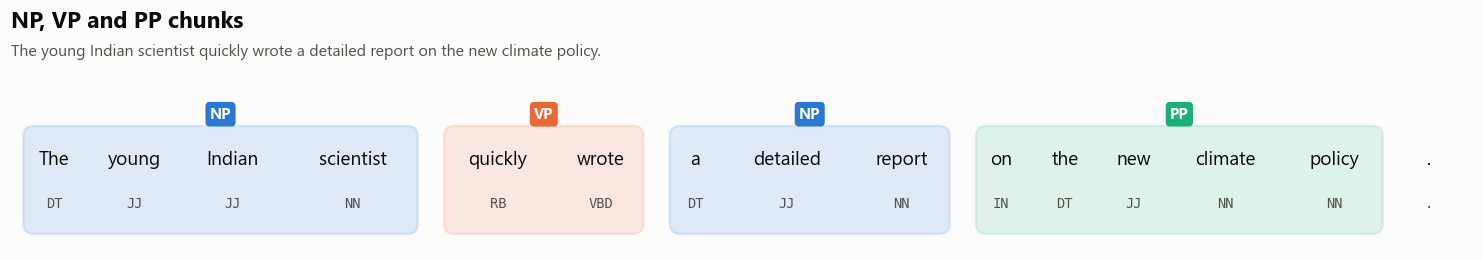

(S
  (NP She/PRP)
  (VP has/VBZ already/RB submitted/VBN)
  (NP her/PRP$ final/JJ thesis/NN)
  (PP to/TO (NP the/DT university/NN))
  ./.)


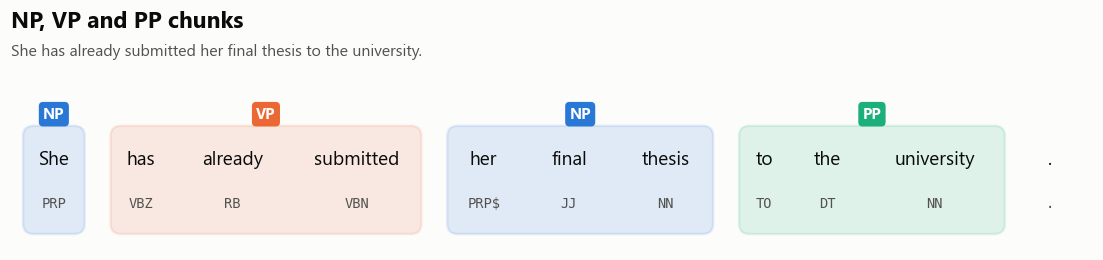

In [11]:
parser = RegexpParser(r"""
  NP: {<DT|PRP\$>?<JJ.*>*<NN.*>+}
      {<PRP>}
  PP: {<IN|TO><NP>}
  VP: {<MD>?<VB.*>*<RB.*>*<VB.*>+}
""")

for s in [sentence, "She has already submitted her final thesis to the university."]:
    tree = parser.parse(pos_tag(word_tokenize(s)))
    print(tree)
    chunk_diagram(tree, "NP, VP and PP chunks", s)

## 2.4 Chinking
A **chink** is a sequence removed from a chunk: chunk everything, then remove verbs, prepositions, adverbs and punctuation.

(S
  (NP The/DT young/JJ Indian/JJ scientist/NN)
  quickly/RB
  wrote/VBD
  (NP a/DT detailed/JJ report/NN)
  on/IN
  (NP the/DT new/JJ climate/NN policy/NN)
  ./.)


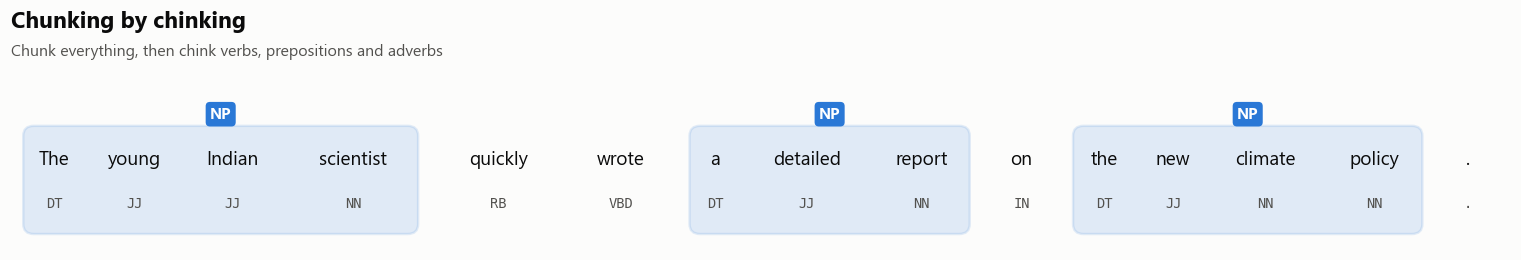

In [12]:
chink_tree = RegexpParser(r"""
  NP: {<.*>+}
      }<VB.*|IN|RB.*|\.>+{
""").parse(tags)
print(chink_tree)
chunk_diagram(chink_tree, "Chunking by chinking", "Chunk everything, then chink verbs, prepositions and adverbs")

## 2.5 IOB tags
Chunks are commonly stored as one tag per word: **B** = beginning of a chunk, **I** = inside, **O** = outside.

In [13]:
from nltk.chunk import tree2conlltags

flat = RegexpParser(r"""
  NP: {<DT|PRP\$>?<JJ.*>*<NN.*>+}
  VP: {<MD>?<VB.*>*<RB.*>*<VB.*>+}
""").parse(tags)
pd.DataFrame(tree2conlltags(flat), columns=["Word", "POS tag", "IOB tag"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Word,The,young,Indian,scientist,quickly,wrote,a,detailed,report,on,the,new,climate,policy,.
POS tag,DT,JJ,JJ,NN,RB,VBD,DT,JJ,NN,IN,DT,JJ,NN,NN,.
IOB tag,B-NP,I-NP,I-NP,I-NP,B-VP,I-VP,B-NP,I-NP,I-NP,O,B-NP,I-NP,I-NP,I-NP,O


## Conclusion
**Part 1:** We tokenized 1,000 tweets, categorized the tokens (words, mentions, hashtags, URLs, emoticons, numbers, punctuation) and POS-tagged them. The standard tagger labelled Twitter-specific tokens as nouns, so we built a Twitter-aware tagger that gives them their own tags.

**Part 2:** We POS-tagged a sentence with Penn Treebank and universal tags, then implemented chunking with regular-expression grammars for NP, VP and PP, chinking, and IOB tags.